# One cavity with beam: MBL-090RFC:RFS-DIG-101

`one_cavity_pulses.parquet` holds one row per RF pulse of the cavity `MBL-090RFC:RFS-DIG-101`, for the cycles with
beam present: 311 pulses from 24 DD captures, 28 to 30 June 2026.

It is written by `ess_dd_subset_features.py` from a filtered copy of the raw DD rows of that cavity (six
waveforms per cycle). The features are computed by the same functions as `cavity_pulses.parquet`; their
definitions are in `ess_dd_heatmaps.ipynb` and in the docstring of `ess_dd_features.py`.

The beam level and the trip timings are not in a filtered file. They are taken here from
`../ess_dd/cavity_pulses.parquet`, joined on capture and cycle.

| File in this folder | Holds |
|---|---|
| `one_cavity_pulses.parquet` | 311 rows, one per pulse: the features and the binned waveforms |
| `ess_dd_subset_features.py` | the script that wrote it; it imports the feature functions of `../ess_dd/ess_dd_features.py` |

To write the table again from a filtered DD parquet:

```
PYTHONPATH=../ess_dd python ess_dd_subset_features.py <filtered.parquet> one_cavity_pulses.parquet 64
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import IsolationForest

INK, MUTED, SURFACE, GRID = "#1a1a19", "#6b6b66", "#fcfcfb", "#e6e5e0"
BLUE, ORANGE, CRITICAL, GREY = "#2a78d6", "#eb6834", "#d03b3b", "#b9b8b0"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#a8322a"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

# A pulse less than this many seconds before a beam trip is the last pulse before that trip.
TRIP_WINDOW_S = 1
# A pulse is cut when its flat top is shorter than this share of the median flat top of the cavity.
CUT_SHARE = 0.9
CONTEXT = ["beam_current", "beam_level", "beam_after_flat_start_us", "seconds_to_next_trip", "seconds_since_last_trip",
           "cycle_rank_from_last"]

pulses = pd.read_parquet("one_cavity_pulses.parquet")
# Beam and trip columns come from the table of all cavities, matched on capture, cycle and cavity.
extra = ["beam_level", "beam_start_us", "beam_len_us", "beam_after_flat_start_us", "seconds_to_next_trip", "seconds_since_last_trip"]
pulses = pulses.merge(pd.read_parquet("../ess_dd/cavity_pulses.parquet", columns=["event_id", "cycle_id", "cavity"] + extra),
                      on=["event_id", "cycle_id", "cavity"], how="left", validate="one_to_one")
pulses = pulses.sort_values("cycle_ts", ignore_index=True)
pulses["before_trip"] = pulses.seconds_to_next_trip < TRIP_WINDOW_S
pulses["is_cut"] = pulses.flat_len < CUT_SHARE * pulses.flat_len.median()
pulses["uncut_before_trip"] = pulses.before_trip & ~pulses.is_cut

# Every numeric per-pulse feature: what the script computed, minus keys, machine state and context.
skip = {"event_id", "cycle_id", "trig_code", "trig_delay", "beam_len", "beam_current", "array_size", "field_base", "fwd_peak_idx",
        "cycles_in_event", "cycle_rank_from_last", "seconds_to_event", "flat_max_dev_pos", "pulse_start_us", "flat_start_us",
        "flat_end_us", "rf_off_us", "beam_start_us", "beam_len_us"} | set(CONTEXT)
FEATURES = [c for c in pulses.columns if pd.api.types.is_float_dtype(pulses[c]) or pd.api.types.is_integer_dtype(pulses[c])]
FEATURES = [c for c in FEATURES if c not in skip and pulses[c].nunique() > 1]
DRIFT = [c for c in FEATURES if c.endswith("_drift")]
print(f"{len(pulses)} pulses, {pulses.event_id.nunique()} captures, {len(FEATURES)} features ({len(DRIFT)} of them drift features)")
print(f"{int(pulses.before_trip.sum())} pulses are the last one before a beam trip; {int(pulses.is_cut.sum())} pulse has its RF cut")
print(pulses[pulses.before_trip][["event_id", "cycle_id", "cycle_ts", "seconds_to_next_trip", "beam_mode", "beam_current", "flat_len", "is_cut"]].to_string(index=False))
pulses.groupby(["beam_mode", "beam_current"]).agg(pulses=("cycle_id", "size"), captures=("event_id", "nunique"))

311 pulses, 24 captures, 32 features (9 of them drift features)
4 pulses are the last one before a beam trip; 1 pulse has its RF cut
   event_id    cycle_id                            cycle_ts  seconds_to_next_trip         beam_mode  beam_current  flat_len  is_cut
16121659801 16121659800 2026-06-28 23:38:47.059873916+00:00              0.601759            RfTest          5158     14758   False
16122602164 16122596526 2026-06-29 18:13:56.056804520+00:00              0.632005 SlowCommissioning         62000      1864    True
16122640949 16122640948 2026-06-29 19:06:49.056658959+00:00              0.604150 SlowCommissioning         61356     14762   False
16122676705 16122676704 2026-06-29 19:49:23.056541801+00:00              0.606724 SlowCommissioning         61758     14762   False


pulses  captures
beam_mode         beam_current                  
Probe             4360              13         1
RfTest            3644              39         3
                  4360              78         6
                  5158             130        10
SlowCommissioning 4360              13         1
                  61356             13         1
                  61758             13         1
                  62000             12         1

## The pulses

Four pulses of this cavity are the last one before a beam trip, each about 0.6 s before the beam permit drops.
In one of them the RF is cut early in the flat top. In the other three the pulse of this cavity is whole.

Each waveform as 64 bin means over the record. Grey: the other pulses. Red: the cut pulse. Black: the three
whole pulses before a trip.

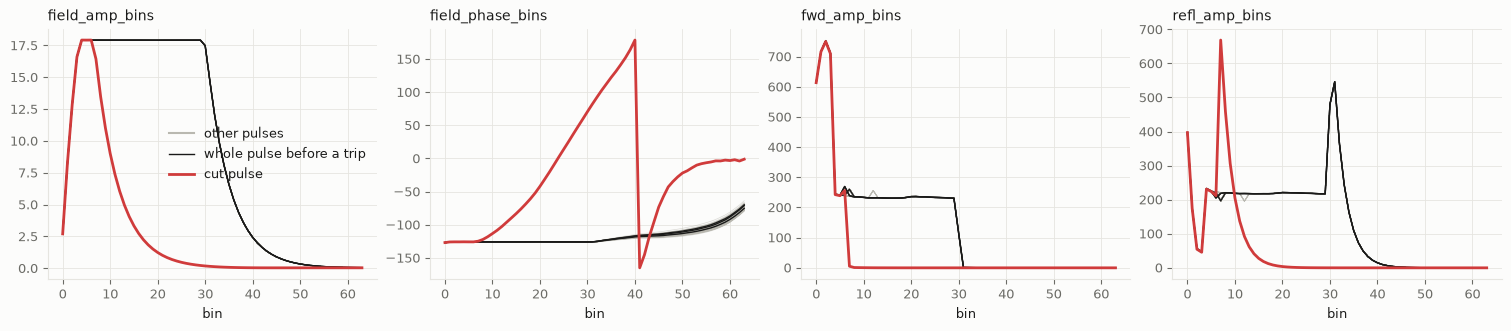

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), constrained_layout=True)
for ax, name in zip(axes, ["field_amp_bins", "field_phase_bins", "fwd_amp_bins", "refl_amp_bins"]):
    ax.plot(np.stack(pulses.loc[~pulses.before_trip, name]).T, color=GREY, linewidth=0.5, alpha=0.5)
    ax.plot(np.stack(pulses.loc[pulses.uncut_before_trip, name]).T, color=INK, linewidth=1)
    ax.plot(np.stack(pulses.loc[pulses.is_cut, name]).T, color=CRITICAL, linewidth=2)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xlabel("bin")
    ax.grid(color=GRID, linewidth=0.6)
axes[0].plot([], [], color=GREY, label="other pulses")
axes[0].plot([], [], color=INK, linewidth=1, label="whole pulse before a trip")
axes[0].plot([], [], color=CRITICAL, linewidth=2, label="cut pulse")
axes[0].legend(frameon=False)
plt.show()

## Features over the 311 pulses

Each feature as its distance to the median of the cavity, in units of its usual spread (1.4826 times the median
absolute deviation). The axis is linear up to 3 and logarithmic beyond, so that normal pulses and the cut pulse
fit on one panel. Pulses are in time order; a vertical line separates two captures.

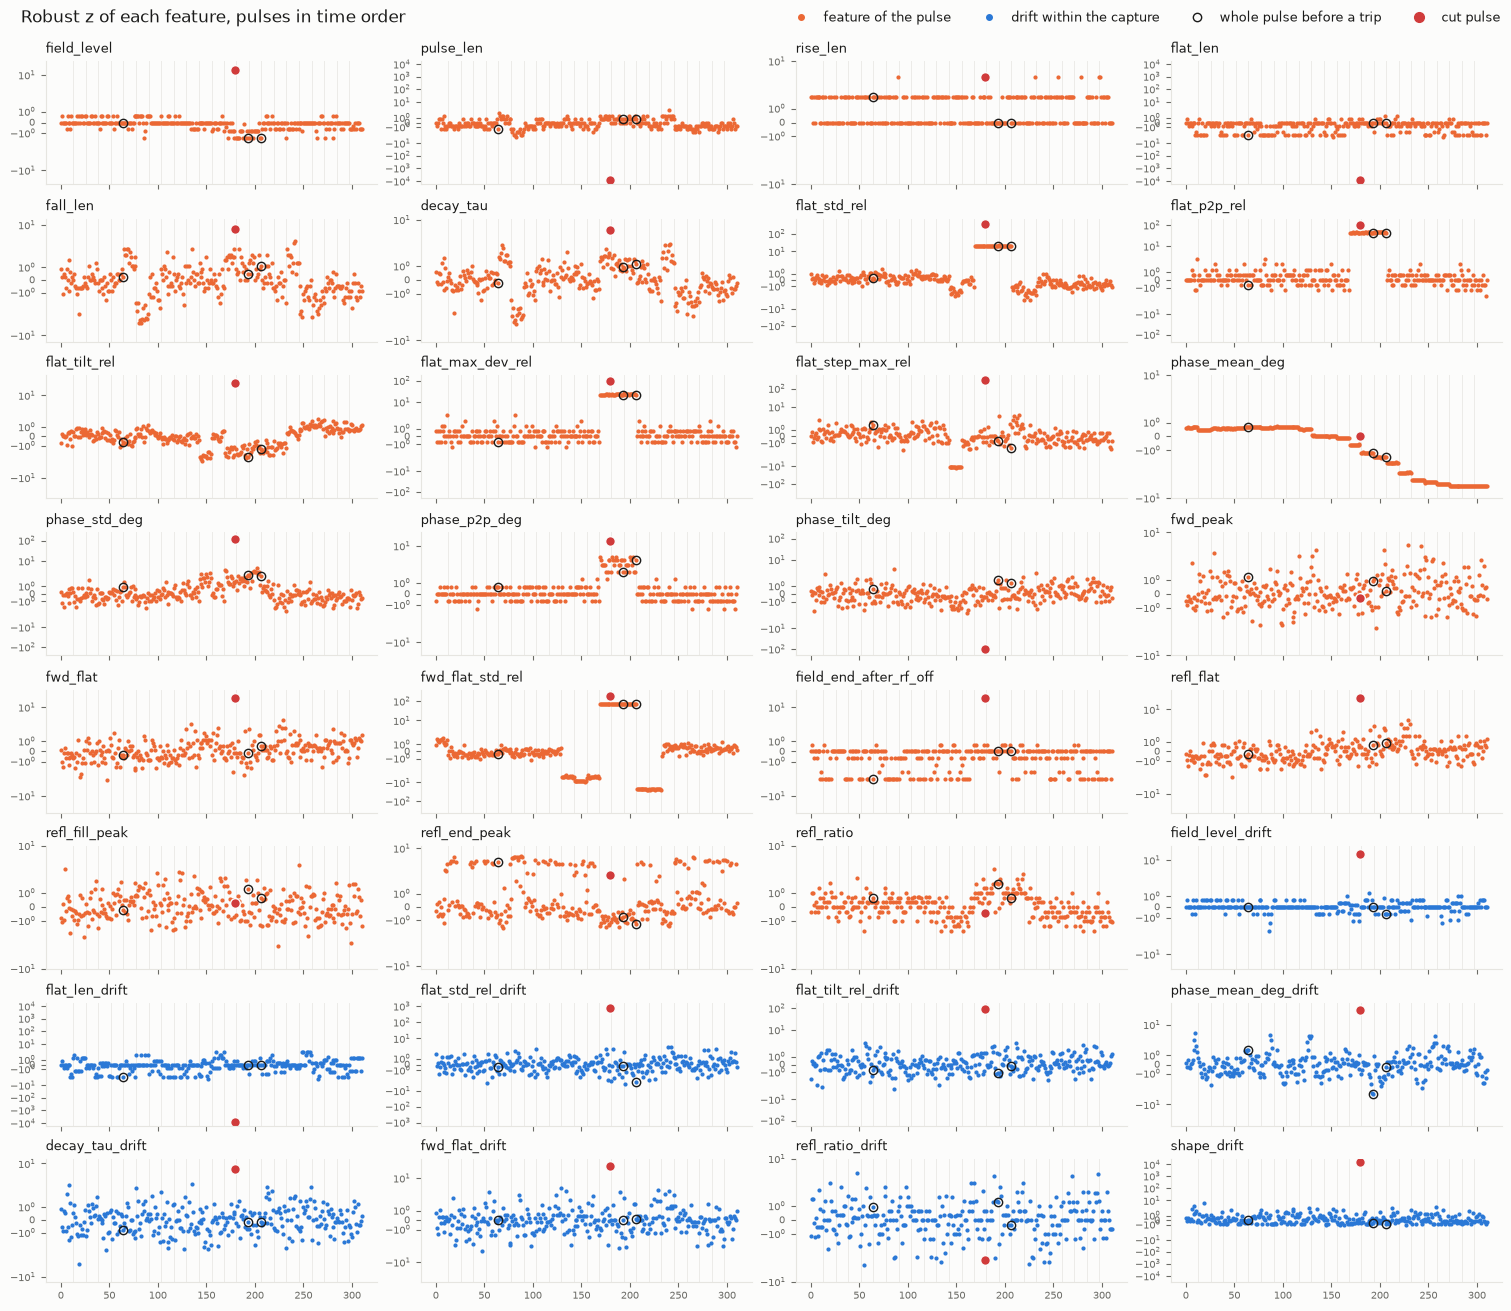

In [3]:
def robust_z(s):
    """Distance to the median in units of the usual spread. Falls back on the standard deviation when more than
    half of the values are equal and the median absolute deviation is 0."""
    spread = 1.4826 * (s - s.median()).abs().median()
    return (s - s.median()) / (spread if spread > 0 else s.std())


z = pulses[FEATURES].apply(robust_z)
edges = np.flatnonzero(pulses.event_id.to_numpy()[1:] != pulses.event_id.to_numpy()[:-1]) + 0.5
cut, whole = np.flatnonzero(pulses.is_cut), np.flatnonzero(pulses.uncut_before_trip)
fig, axes = plt.subplots(8, 4, figsize=(15, 13), sharex=True, constrained_layout=True)
for ax, feature in zip(axes.ravel(), FEATURES):
    ax.vlines(edges, -1e6, 1e6, color=GRID, linewidth=0.5)
    ax.plot(z[feature].to_numpy(), color=BLUE if feature in DRIFT else ORANGE, linewidth=0, marker="o", markersize=2)
    ax.plot(whole, z[feature].to_numpy()[whole], linewidth=0, marker="o", markersize=6, color="none", markeredgecolor=INK)
    ax.plot(cut, z[feature].to_numpy()[cut], linewidth=0, marker="o", markersize=7, color=CRITICAL, markeredgecolor=SURFACE)
    ax.set_yscale("symlog", linthresh=3)
    limit = max(10, float(np.nanmax(np.abs(z[feature]))) * 2)
    ax.set_ylim(-limit, limit)
    ax.set_title(feature, loc="left", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
axes[0, 0].plot([], [], linewidth=0, marker="o", markersize=4, color=ORANGE, label="feature of the pulse")
axes[0, 0].plot([], [], linewidth=0, marker="o", markersize=4, color=BLUE, label="drift within the capture")
axes[0, 0].plot([], [], linewidth=0, marker="o", markersize=6, color="none", markeredgecolor=INK, label="whole pulse before a trip")
axes[0, 0].plot([], [], linewidth=0, marker="o", markersize=7, color=CRITICAL, label="cut pulse")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper right", ncols=4, frameon=False)
fig.suptitle("Robust z of each feature, pulses in time order", x=0.01, ha="left", fontsize=12)
plt.show()

## Feature against feature

Correlation between two features over the 311 pulses. Spearman works on ranks, Pearson on the values.
With one cavity there is nothing to pool, so the features are used as they are.

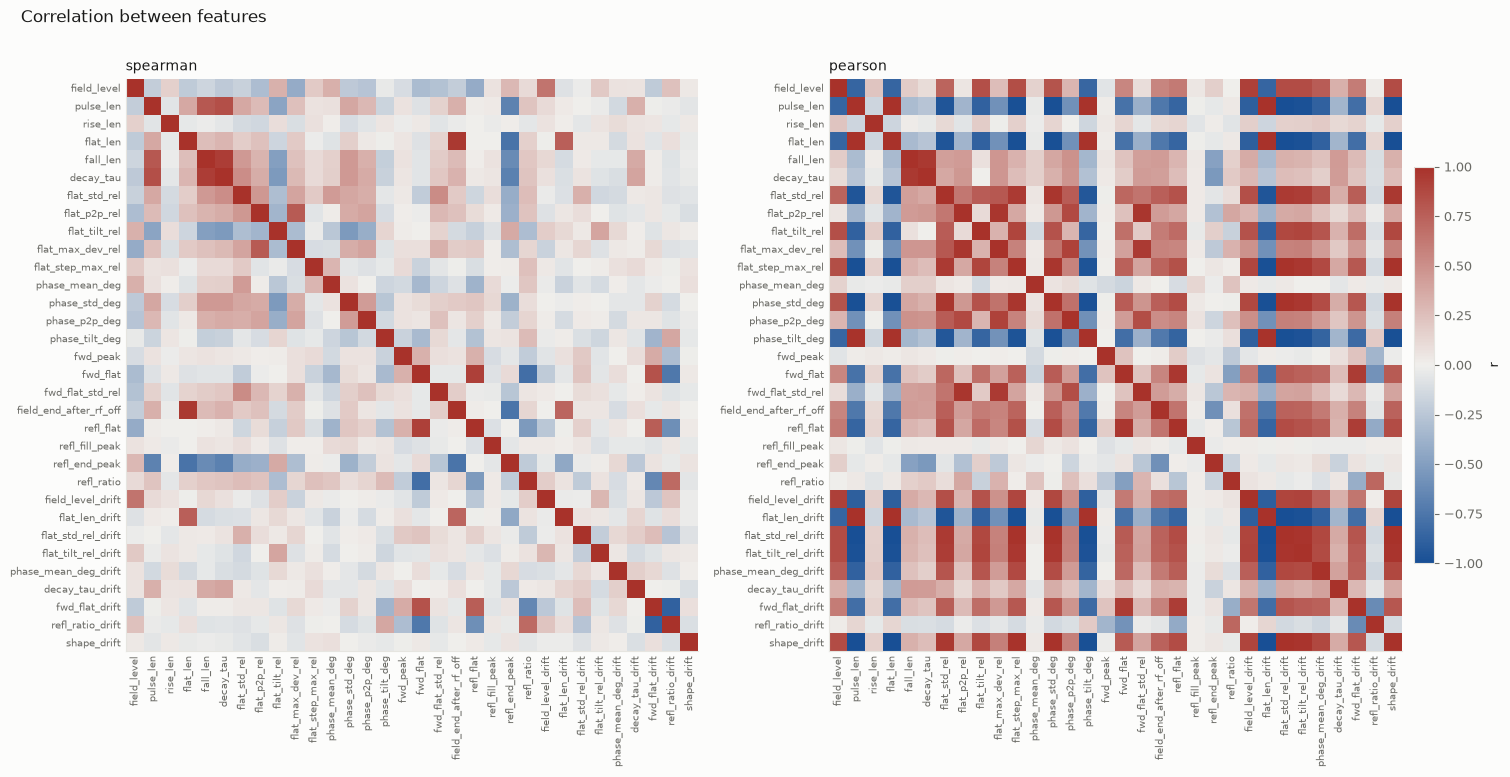

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.6), constrained_layout=True)
for ax, method in zip(axes, ["spearman", "pearson"]):
    image = ax.imshow(pulses[FEATURES].corr(method=method).to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
    ax.tick_params(length=0)
    ax.set_title(method, loc="left", fontsize=10)
fig.colorbar(image, ax=axes, shrink=0.6, pad=0.01, label="r")
fig.suptitle("Correlation between features", x=0.01, ha="left", fontsize=12)
plt.show()

## Feature against context

Beam current and the trip timings are constant within a capture, so those columns compare the 24 captures.

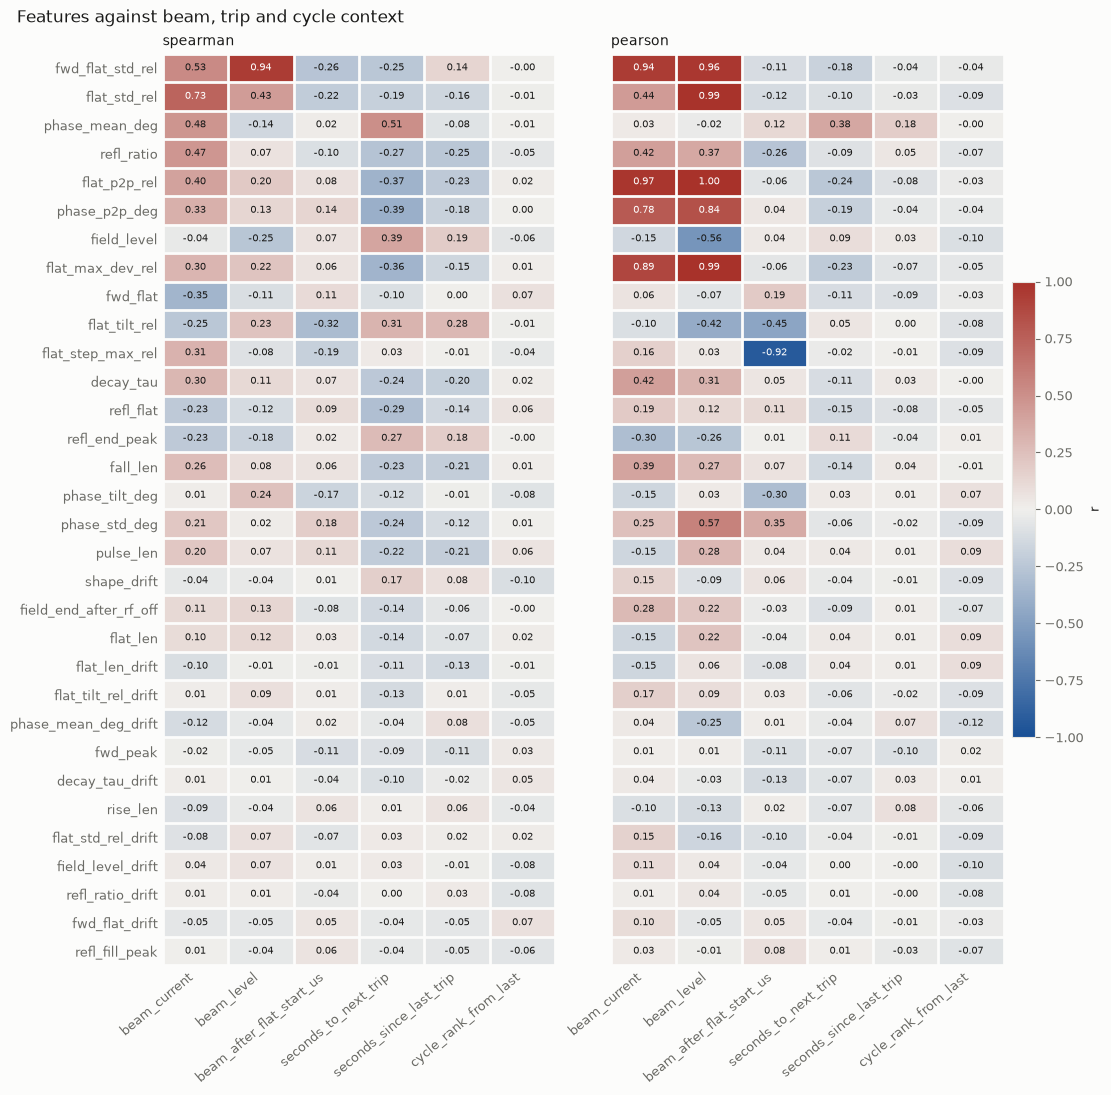

In [5]:
order = pulses[FEATURES + CONTEXT].corr(method="spearman").loc[FEATURES, CONTEXT].abs().max(axis=1).sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(11, 0.27 * len(FEATURES) + 2.2), sharey=True, constrained_layout=True)
for ax, method in zip(axes, ["spearman", "pearson"]):
    grid = pulses[FEATURES + CONTEXT].astype(float).corr(method=method).loc[order, CONTEXT]
    image = ax.imshow(grid.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    for (i, j), r in np.ndenumerate(grid.to_numpy()):
        if not np.isnan(r):
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(r) > 0.6 else INK)
    ax.set_xticks(range(len(CONTEXT)), CONTEXT, rotation=40, ha="right")
    ax.set_yticks(range(len(order)), order)
    ax.set_xticks(np.arange(-0.5, len(CONTEXT)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(order)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.spines[:].set_visible(False)
    ax.set_title(method, loc="left", fontsize=10)
fig.colorbar(image, ax=axes, shrink=0.5, pad=0.01, label="r")
fig.suptitle("Features against beam, trip and cycle context", x=0.01, ha="left", fontsize=12)
plt.show()

## An anomaly score without labels

An isolation forest is fitted on all features of the 311 pulses. It needs no label: it scores a pulse by how few
random cuts are needed to separate it from the others. A high score is an unusual pulse.

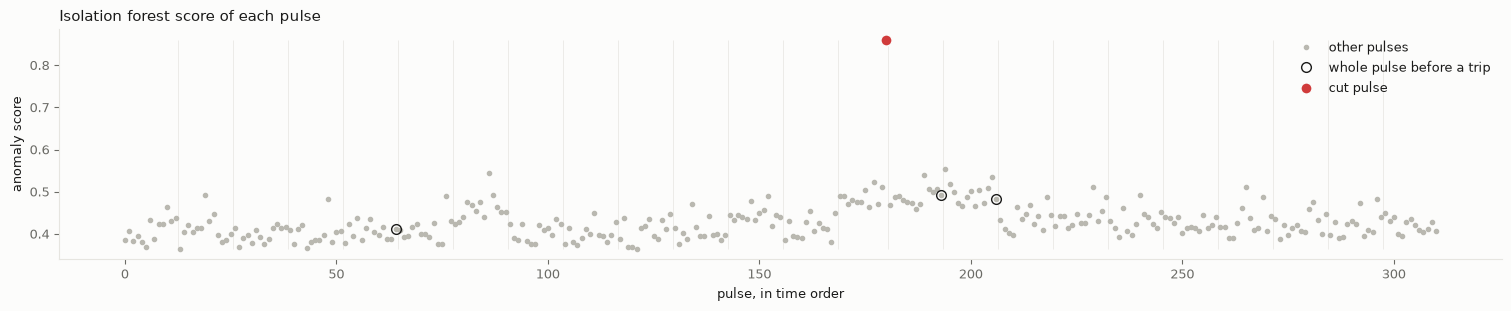

,event_id,cycle_id,cycle_ts,anomaly_score,is_cut,before_trip,beam_mode,beam_current,seconds_to_next_trip,flat_len,shape_drift
180,16122602164,16122596526,2026-06-29 18:13:56.056804520+00:00,0.860410,True,True,SlowCommissioning,62000,0.632005,1864,0.537460
194,16122676705,16122676536,2026-06-29 19:49:11.056542346+00:00,0.553860,False,False,SlowCommissioning,61758,12.606723,14759,0.000043
86,16121745364,16121745298,2026-06-29 01:20:34.059593765+00:00,0.544724,False,False,RfTest,5158,324.609627,14758,0.000057
189,16122640949,16122640892,2026-06-29 19:06:45.056659140+00:00,0.539596,False,False,SlowCommissioning,61356,4.604150,14762,0.000034
205,16122676705,16122676690,2026-06-29 19:49:22.056541847+00:00,0.534976,False,False,SlowCommissioning,61758,1.606724,14764,0.000042
177,16122602164,16122596484,2026-06-29 18:13:53.056804656+00:00,0.521905,False,False,SlowCommissioning,62000,3.632005,14761,0.000022
195,16122676705,16122676550,2026-06-29 19:49:12.056542301+00:00,0.517324,False,False,SlowCommissioning,61758,11.606723,14762,0.000046
265,16122954964,16122954870,2026-06-30 01:20:32.055630322+00:00,0.510804,False,False,RfTest,4360,NaN,14757,0.000122
179,16122602164,16122596512,2026-06-29 18:13:55.056804565+00:00,0.510162,False,False,SlowCommissioning,62000,1.632005,14763,0.000055
229,16122803764,16122803712,2026-06-29 22:20:35.056125629+00:00,0.510129,False,False,Probe,4360,22.602794,14762,0.000066


In [6]:
# The forest splits on thresholds, so the scale of a feature does not matter; a missing value is set to the median.
X = pulses[FEATURES].fillna(pulses[FEATURES].median()).to_numpy()
forest = IsolationForest(n_estimators=500, random_state=0).fit(X)
pulses["anomaly_score"] = -forest.score_samples(X)

fig, ax = plt.subplots(figsize=(15, 3), constrained_layout=True)
ax.vlines(edges, pulses.anomaly_score.min(), pulses.anomaly_score.max(), color=GRID, linewidth=0.5)
ax.plot(pulses.anomaly_score.to_numpy(), linewidth=0, marker="o", markersize=3, color=GREY, label="other pulses")
ax.plot(whole, pulses.anomaly_score.to_numpy()[whole], linewidth=0, marker="o", markersize=7, color="none", markeredgecolor=INK, label="whole pulse before a trip")
ax.plot(cut, pulses.anomaly_score.to_numpy()[cut], linewidth=0, marker="o", markersize=8, color=CRITICAL, markeredgecolor=SURFACE, label="cut pulse")
ax.set_xlabel("pulse, in time order")
ax.set_ylabel("anomaly score")
ax.set_title("Isolation forest score of each pulse", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.show()

pulses.sort_values("anomaly_score", ascending=False).head(10)[
    ["event_id", "cycle_id", "cycle_ts", "anomaly_score", "is_cut", "before_trip", "beam_mode", "beam_current", "seconds_to_next_trip", "flat_len", "shape_drift"]]

## Feature importance for anomaly detection

Two measures per feature.

- **Weight in the anomaly score.** The values of the feature are shuffled between pulses and the forest scores
  the pulses again. The more the ranking of the pulses changes (1 minus the rank correlation with the original
  scores, mean of 20 shuffles), the more the score depends on that feature.
- **Distance of the cut pulse.** The robust z of the cut pulse on that feature. The black tick is the 99th
  percentile of the pulses that are not before a trip: a bar that passes its tick separates the cut pulse from
  99 % of them. The open diamond is the largest robust z among the three whole pulses before a trip.

The cavity has one cut pulse in this file. The right panel says which features catch that pulse; it does not say
how they would do on other faults. Where the diamond sits left of the tick, the feature sees nothing in the three
trips that left the pulse of this cavity whole.

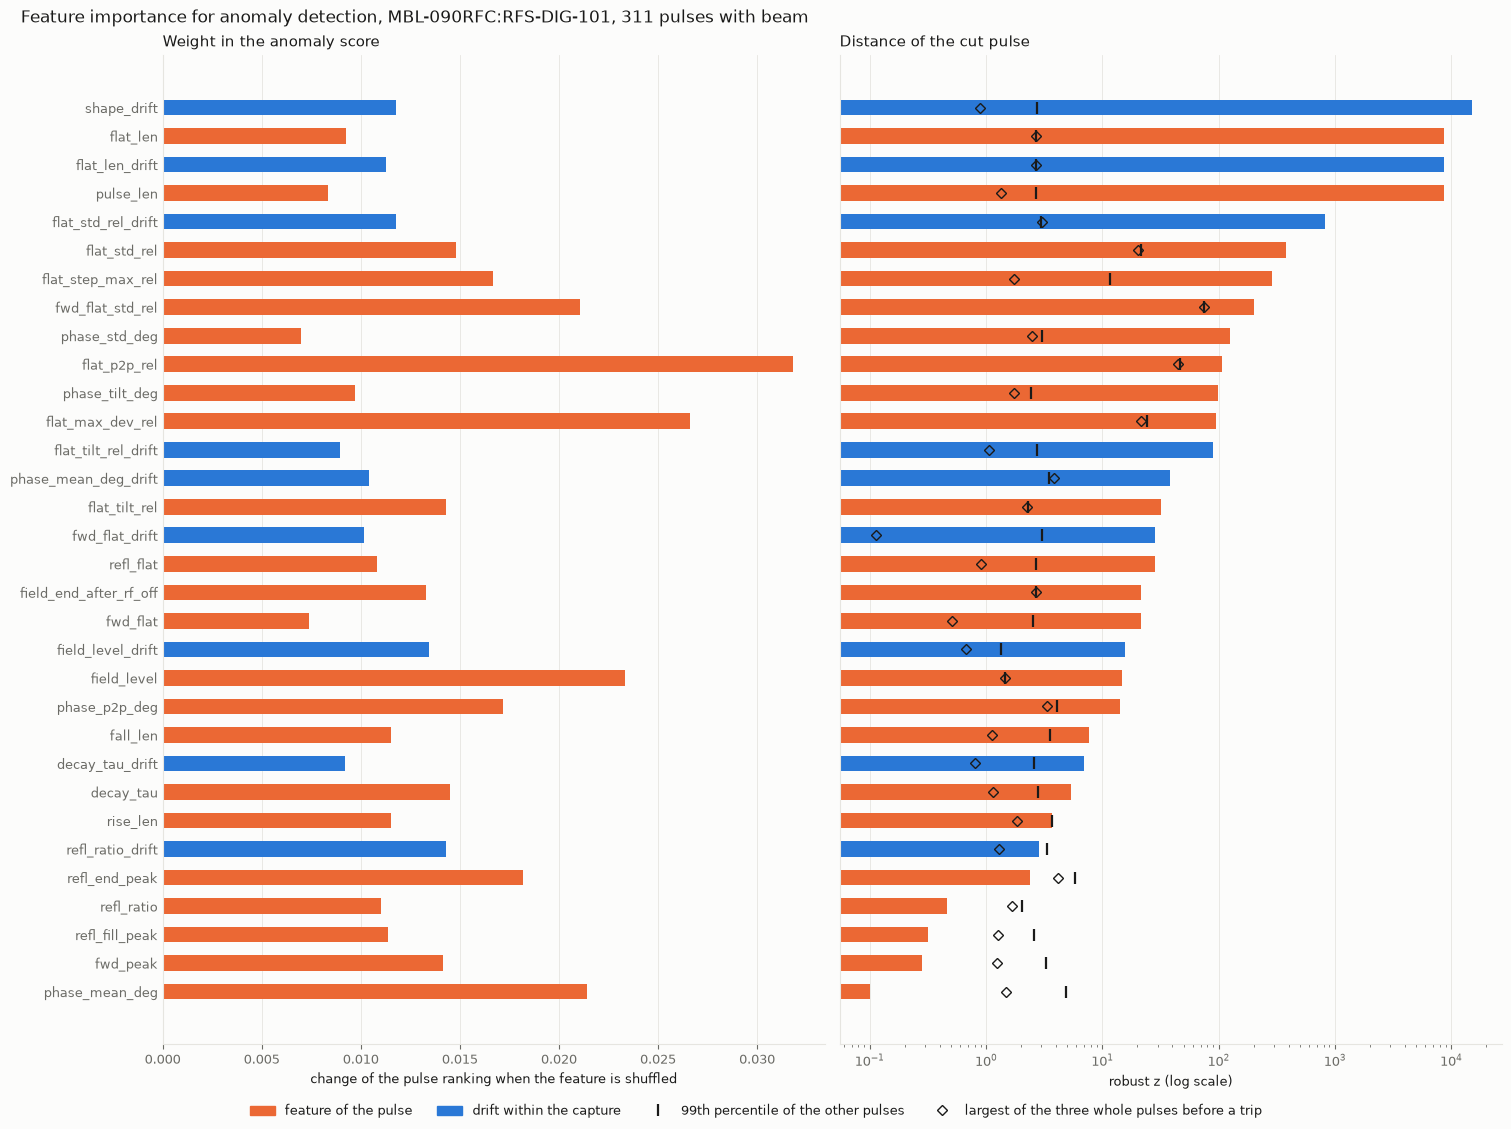

,weight_in_score,cut_distance,whole_before_trip_distance,others_p99,catches_cut,catches_whole_before_trip
shape_drift,0.012,15009.030,0.892,2.723,True,False
flat_len,0.009,8699.582,2.698,2.698,True,False
flat_len_drift,0.011,8699.582,2.698,2.698,True,False
pulse_len,0.008,8694.860,1.349,2.698,True,False
flat_std_rel_drift,0.012,821.988,3.036,2.963,True,True
flat_std_rel,0.015,383.734,20.449,21.509,True,False
flat_step_max_rel,0.017,290.182,1.745,11.751,True,False
fwd_flat_std_rel,0.021,201.615,74.861,75.529,True,False
phase_std_deg,0.007,126.539,2.485,3.016,True,False
flat_p2p_rel,0.032,106.643,44.597,46.581,True,False


In [7]:
def ranks(a):
    return pd.Series(a).rank().to_numpy()


rng = np.random.default_rng(0)
base = ranks(pulses.anomaly_score)
weight = {}
for j, feature in enumerate(FEATURES):
    change = []
    for _ in range(20):
        shuffled = X.copy()
        shuffled[:, j] = rng.permutation(shuffled[:, j])
        change.append(1 - np.corrcoef(base, ranks(-forest.score_samples(shuffled)))[0, 1])
    weight[feature] = np.mean(change)

importance = pd.DataFrame({"weight_in_score": pd.Series(weight),
                           "cut_distance": z[pulses.is_cut].abs().max(),
                           "whole_before_trip_distance": z[pulses.uncut_before_trip].abs().max(),
                           "others_p99": z[~pulses.before_trip].abs().quantile(0.99)})
importance["catches_cut"] = importance.cut_distance > importance.others_p99
importance["catches_whole_before_trip"] = importance.whole_before_trip_distance > importance.others_p99
importance = importance.sort_values("cut_distance", ascending=True)

colors = [BLUE if f in DRIFT else ORANGE for f in importance.index]
y = np.arange(len(importance))
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 0.3 * len(importance) + 1.6), sharey=True, constrained_layout=True)
left.barh(y, importance.weight_in_score, height=0.55, color=colors)
left.set_xlabel("change of the pulse ranking when the feature is shuffled")
left.set_title("Weight in the anomaly score", loc="left", fontsize=11)
right.barh(y, importance.cut_distance.clip(lower=0.1), height=0.55, color=colors)
right.plot(importance.others_p99, y, linewidth=0, marker="|", markersize=9, markeredgewidth=1.6, color=INK, label="99th percentile of the other pulses")
right.plot(importance.whole_before_trip_distance.clip(lower=0.1), y, linewidth=0, marker="D", markersize=5, color="none", markeredgecolor=INK,
           label="largest of the three whole pulses before a trip")
right.set_xscale("log")
right.set_xlabel("robust z (log scale)")
right.set_title("Distance of the cut pulse", loc="left", fontsize=11)
for ax in (left, right):
    ax.set_yticks(y, importance.index)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)] + right.get_legend_handles_labels()[0]
labels = ["feature of the pulse", "drift within the capture"] + right.get_legend_handles_labels()[1]
fig.legend(handles, labels, loc="outside lower center", ncols=4, frameon=False)
fig.suptitle("Feature importance for anomaly detection, MBL-090RFC:RFS-DIG-101, 311 pulses with beam", x=0.01, ha="left", fontsize=12)
plt.show()

importance.sort_values("cut_distance", ascending=False).round(3)